# M504 AI and Applications

## **Project Title:** Explanatory Data Analysis of New York City Airbnb Listings

1.   List item
2.   List item



**Student Name:** Mayank Rikhari  
**Student Id:** GH1056331  
**Module:** M504A AI and Applications  
**Dataset:** `AB_NYC_2019.csv`


## 1. Business Context

The client is considered to be the Airbnb management team. The dataset contains listing, host, location, room-type, price, review and availability information for New York City. As a data analyst, I have to identify differences in pricing, supply, availability and review activity that can support marketplace decisions.

**Dataset source:** Dgomonov (2019), *New York City Airbnb Open Data* (Kaggle).  
https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data


## 2. Dataset Exploration

This dataset consists of 48895 listing and 16 fields. Exploration checks its structure, data types, missing values, duplicates, categorical distributions, descriptive statistics and unusual price values before preprocessing.


In [555]:
# libraries
import pandas as pd
import matplotlib.pyplot as gph_drw

src_dt = pd.read_csv('AB_NYC_2019.csv')

# Display the first five records
src_dt.head(2)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355


**Interpretation**  
The sample confirms that the dataset contains listing, host, location, room-type, price, review and availability information required for the analysis.


In [556]:
# size of the dataset.
print("Rows:", src_dt.shape[0])
print("Columns:", src_dt.shape[1])

# Display and Rename variable .
src_dt = src_dt.rename(columns={
    'id': 'listing_id',
    'name': 'listing_name',
    'host_id': 'host_identifier',
    'host_name': 'host_full_name',
    'neighbourhood_group': 'neighbourhood_area',
    'neighbourhood': 'neighbourhood_name',
    'latitude': 'location_latitude',
    'longitude': 'location_longitude',
    'room_type': 'accommodation_category',
    'price': 'nightly_rate',
    'minimum_nights': 'minimum_stay',
    'number_of_reviews': 'review_count',
    'last_review': 'latest_review_date',
    'reviews_per_month': 'monthly_review_frequency',
    'calculated_host_listings_count': 'host_listing_total',
    'availability_365': 'yearly_availability'
})

# Display the final variable names
print("Final variable names:")
print(src_dt.columns.tolist())

Rows: 48895
Columns: 16
Final variable names:
['listing_id', 'listing_name', 'host_identifier', 'host_full_name', 'neighbourhood_area', 'neighbourhood_name', 'location_latitude', 'location_longitude', 'accommodation_category', 'nightly_rate', 'minimum_stay', 'review_count', 'latest_review_date', 'monthly_review_frequency', 'host_listing_total', 'yearly_availability']


Interpretation

A total of 48,895 records and 16 columns. The variables include listing and host identifiers, location, accommodation type, price, minimum nights, reviews and annual availability.

In [580]:
# Check data types
src_dt.dtypes

,0
listing_id,int64
listing_name,object
host_identifier,int64
host_full_name,object
neighbourhood_area,object
neighbourhood_name,object
location_latitude,float64
location_longitude,float64
accommodation_category,object
nightly_rate,int64


**Interpretation**  
Most variables are numeric or categorical. `last_review` is stored as text and therefore needs conversion to a date during preprocessing.


In [558]:
#  missing values.
missing = src_dt.isnull().sum()

#percentage of missing values.
missing_pct = (missing / len(src_dt) * 100).round(2)

#columns with missing values
missing_summary = pd.DataFrame({'Missing Values': missing, 'Missing %': missing_pct})
missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Missing %
listing_name,16,0.03
host_full_name,21,0.04
latest_review_date,10052,20.56
monthly_review_frequency,10052,20.56


**Interpretation**  
Missing values occur in `name`, `host_name`, `last_review` and `reviews_per_month`. The two review-related fields each have 10,052 missing values (20.56%), making them the main data-quality issue.


In [559]:
#exact duplicate rows.
print("Duplicate rows:", src_dt.duplicated().sum())

#whether listing IDs are repeated.
print("Duplicate listing IDs:", src_dt['listing_id'].duplicated().sum())

Duplicate rows: 0
Duplicate listing IDs: 0


Interpretation

No duplicate rows are present and no repeated listing IDs so no duplicate records to remove.


In [582]:
#numerical descriptive statistics
src_dt[['nightly_rate', 'review_count']].describe()

,nightly_rate,review_count
count,48895.000000,48895.000000
mean,152.720687,23.274466
std,240.154170,44.550582
min,0.000000,0.000000
25%,69.000000,1.000000
50%,106.000000,5.000000
75%,175.000000,24.000000
max,10000.000000,629.000000


Interpretation

The median price is 106 dollors  while the maximum is 10,000. The large difference indicates a strongly right-skewed price distribution and justifies checking extreme values.


In [561]:
# Count listings by room type and neighbourhood group.
print("Accommodation_category:")
print(src_dt['accommodation_category'].value_counts())

print("\nNeighbourhood area:")
print(src_dt['neighbourhood_area'].value_counts())

# Compare room types across neighbourhood groups.
print("\nRoom type by neighbourhood area:")
display(pd.crosstab(src_dt['neighbourhood_area'], src_dt['accommodation_category']))

Accommodation_category:
accommodation_category
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64

Neighbourhood area:
neighbourhood_area
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

Room type by neighbourhood area:


accommodation_category,Entire home/apt,Private room,Shared room
neighbourhood_area,,,
Bronx,379,652,60
Brooklyn,9559,10132,413
Manhattan,13199,7982,480
Queens,2096,3372,198
Staten Island,176,188,9


Interpretation

There are three types of rooms in the data and five neighbourhood groups, of which there is a significant difference in count. This gives useful dimensions for business analysis from a categorical point of view.


In [562]:
#lowest and highest prices
print("Minimum price:", src_dt['nightly_rate'].min())
print("Maximum price:", src_dt['nightly_rate'].max())

# ten most expensive listings for inspection
display(src_dt[['listing_name','neighbourhood_area','neighbourhood_name','accommodation_category','nightly_rate']]
        .sort_values('nightly_rate', ascending=False).head(10))

Minimum price: 0
Maximum price: 10000


,listing_name,neighbourhood_area,neighbourhood_name,accommodation_category,nightly_rate
29238,1-BR Lincoln Center,Manhattan,Upper West Side,Entire home/apt,10000
9151,Furnished room in Astoria apartment,Queens,Astoria,Private room,10000
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Greenpoint,Entire home/apt,10000
6530,Spanish Harlem Apt,Manhattan,East Harlem,Entire home/apt,9999
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Lower East Side,Entire home/apt,9999
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Lower East Side,Private room,9999
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Tribeca,Entire home/apt,8500
4377,Film Location,Brooklyn,Clinton Hill,Entire home/apt,8000
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Upper East Side,Entire home/apt,7703
42523,70' Luxury MotorYacht on the Hudson,Manhattan,Battery Park City,Entire home/apt,7500


**Interpretation**  
The wide price range suggests that some listings may be unusually expensive. These observations should be inspected before deciding whether they are data errors or legitimate high-priced listings.


In [563]:
# Eliminate listings that have an invalid zero nightly price.
zero_price = src_dt[src_dt['nightly_rate'] == 0]
print("Zero-price listings:", len(zero_price))
print("Percentage:", round(len(zero_price) / len(src_dt) * 100, 2), "%")
display(zero_price[['listing_name','neighbourhood_area','neighbourhood_name','accommodation_category','nightly_rate']])

Zero-price listings: 11
Percentage: 0.02 %


,listing_name,neighbourhood_area,neighbourhood_name,accommodation_category,nightly_rate
23161,"Huge Brooklyn Brownstone Living, Close to it all.",Brooklyn,Bedford-Stuyvesant,Private room,0
25433,★Hostel Style Room | Ideal Traveling Buddies★,Bronx,East Morrisania,Private room,0
25634,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Brooklyn,Bushwick,Private room,0
25753,"Sunny, Quiet Room in Greenpoint",Brooklyn,Greenpoint,Private room,0
25778,Modern apartment in the heart of Williamsburg,Brooklyn,Williamsburg,Entire home/apt,0
25794,Spacious comfortable master bedroom with nice ...,Brooklyn,Bedford-Stuyvesant,Private room,0
25795,Contemporary bedroom in brownstone with nice view,Brooklyn,Bedford-Stuyvesant,Private room,0
25796,Cozy yet spacious private brownstone bedroom,Brooklyn,Bedford-Stuyvesant,Private room,0
26259,the best you can find,Manhattan,Murray Hill,Entire home/apt,0
26841,Coliving in Brooklyn! Modern design / Shared room,Brooklyn,Bushwick,Shared room,0


Interpretation

There are 11 zero-price listings (0.02%). A zero nightly price is not suitable for a pricing analysis, so these records are removed during preprocessing.


In [564]:
#IQR rule to identify price outliers.
q1 = src_dt['nightly_rate'].quantile(0.25)
q3 = src_dt['nightly_rate'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = src_dt[src_dt['nightly_rate'] > upper]
print("Q1:", q1, "Q3:", q3)
print("IQR:", iqr)
print("Upper limit:", upper)
print("Price outliers:", len(outliers))

Q1: 69.0 Q3: 175.0
IQR: 106.0
Upper limit: 334.0
Price outliers: 2972


Interpretation

The values at the upper quartile are 334 dollors and 2,972 listings are greater than 334 dollors. The values are kept since a high Airbnb price doesn't necessarily mean an error, and without evidence they should not be removed.


## 3. Data Preprocessing

The above Quality checks precede the pre-processing. Zero-price listings are excluded as they are not valid to analyze pricing. When the name is missing, it is substituted with Unknown. The listings that do not have any review recorded have a missing review_per_month value, which is filled in with 0. If no last_review is provided, it is not replaced with a value because it's hard to determine what that value should be. The date field is converted to datetime.


In [565]:
#Clean up listings that don't have a correct zero nightly price.
src_dt_clean = src_dt[src_dt['nightly_rate'] > 0].copy()
print("Original rows:", len(src_dt))
print("Cleaned rows:", len(src_dt_clean))
print("Rows removed:", len(src_dt) - len(src_dt_clean))

Original rows: 48895
Cleaned rows: 48884
Rows removed: 11


**Interpretation**  
After the 11 zero-price records are eliminated, 48,884 listings remain. Currently, no other records are deleted.


In [566]:
#Adding zero to any monthly review ratings that are missing
src_dt_clean['monthly_review_frequency'] = src_dt_clean['monthly_review_frequency'].fillna(0)

# Using a neutral label in place of the missing listing and host names
src_dt_clean['listing_name'] = src_dt_clean['listing_name'].fillna('Unknown')
src_dt_clean['host_full_name'] = src_dt_clean['host_full_name'].fillna('Unknown')

print("Missing monthly_review_frequency:", src_dt_clean['monthly_review_frequency'].isna().sum())
print("Missing name:", src_dt_clean['listing_name'].isna().sum())
print("Missing host_name:", src_dt_clean['host_full_name'].isna().sum())

Missing monthly_review_frequency: 0
Missing name: 0
Missing host_name: 0


**Interpretation**  
Valid listings are not deleted in order to manage missing names. Listings without recorded reviews have reviews_per_month set to 0, while listings with missing names have a neutral label.


In [567]:
# Transforming last_review from text to datetime
src_dt_clean['latest_review_date'] = pd.to_datetime(src_dt_clean['latest_review_date'], errors='coerce')

# Verifying the final type and any missing values
print("last_review type:", src_dt_clean['latest_review_date'].dtype)
print(src_dt_clean.isna().sum()[src_dt_clean.isna().sum() > 0])

last_review type: datetime64[ns]
latest_review_date    10051
dtype: int64


Interpretation

Now, last_review is a datetime variable. Since there is no trustworthy review date to impute, the remaining missing values are kept.

In [568]:
# Final quality checks after preprocessing
print("Final shape:", src_dt_clean.shape)
print("Duplicate rows:", src_dt_clean.duplicated().sum())
print("Duplicate IDs:", src_dt_clean['listing_id'].duplicated().sum())
print("Non-positive prices:", (src_dt_clean['nightly_rate'] <= 0).sum())

Final shape: (48884, 16)
Duplicate rows: 0
Duplicate IDs: 0
Non-positive prices: 0


**Interpretation**  
The cleaned dataset contains 48,884 rows and 16 columns. There are no duplicate rows or IDs and no non-positive prices.


## 4. Explanatory Data Analysis


## Business question 1 — Which neighborhood group's average Airbnb listing price is the highest?

**Business importance**  
Comparing price levels across neighbourhood groups can support pricing strategy and identify higher- and lower-priced markets.


,count,mean,median
neighbourhood_area,,,
Manhattan,21660,196.884903,150.0
Brooklyn,20095,124.438915,90.0
Staten Island,373,114.812332,75.0
Queens,5666,99.517649,75.0
Bronx,1090,87.577064,65.0


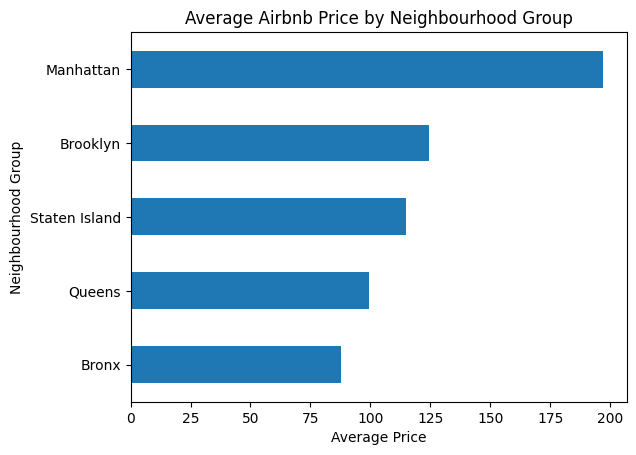

In [569]:
# Group listings by neighbourhood group and calculate price statistics
price_area = src_dt_clean.groupby('neighbourhood_area')['nightly_rate'].agg(['count','mean','median']).sort_values('mean', ascending=False)
display(price_area)

# Ploting the average price for an easier comparison
price_area['mean'].sort_values().plot(kind='barh')
gph_drw.title('Average Airbnb Price by Neighbourhood Group')
gph_drw.xlabel('Average Price')
gph_drw.ylabel('Neighbourhood Group')
gph_drw.show()

**Interpretation**  
Manhattan is the highest mean and median price, the Bronx is the lowest mean. However, the difference between them also indicates that it's beneficial to use both measures, as a very high priced listing could influence the mean in an upward trend..


## Business Question 2 — What is the difference in price between Airbnb room types?

**Business importance**  
One of the key components of Airbnb is room type. The distribution of room prices by type provides a good indication of some of the typical market positions..


,count,mean,median
accommodation_category,,,
Entire home/apt,25407,211.810918,160.0
Private room,22319,89.809131,70.0
Shared room,1158,70.248705,45.0


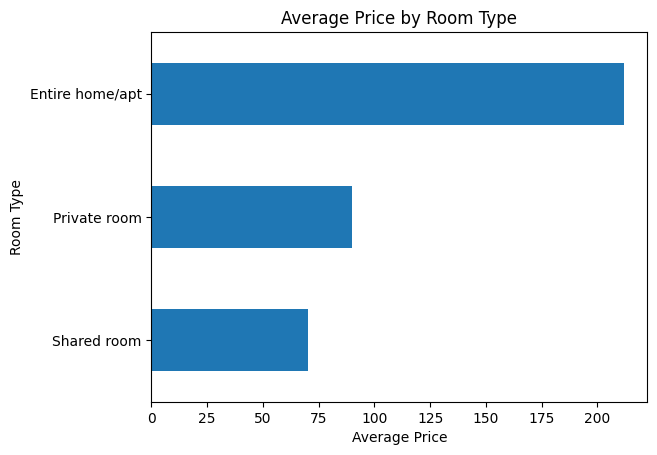

In [570]:
# Compare price statistics across room types
room_price = src_dt_clean.groupby('accommodation_category')['nightly_rate'].agg(['count','mean','median']).sort_values('mean', ascending=False)
display(room_price)

# Plot mean price by room type
room_price['mean'].sort_values().plot(kind='barh')
gph_drw.title('Average Price by Room Type')
gph_drw.xlabel('Average Price')
gph_drw.ylabel('Room Type')
gph_drw.show()

**Interpretation**  
The homes/apartments had the highest mean ( $211.81) and median ( $160) prices. A shared room typically costs 70.25 dollars, while a private room typically costs 89.81 dollars. The results do not establish causation, but they do show distinct statistical disparities in pricing by kind of room.


## Business Question 3 — In which neighbourhoods are there the most Airbnb listings?

**Business importance**  
Recognising high supply areas enables the business to comprehend where listings are being focused and where there might be more competition.


,count
neighbourhood_name,
Williamsburg,3919
Bedford-Stuyvesant,3710
Harlem,2658
Bushwick,2462
Upper West Side,1971
Hell's Kitchen,1958
East Village,1853
Upper East Side,1798
Crown Heights,1564


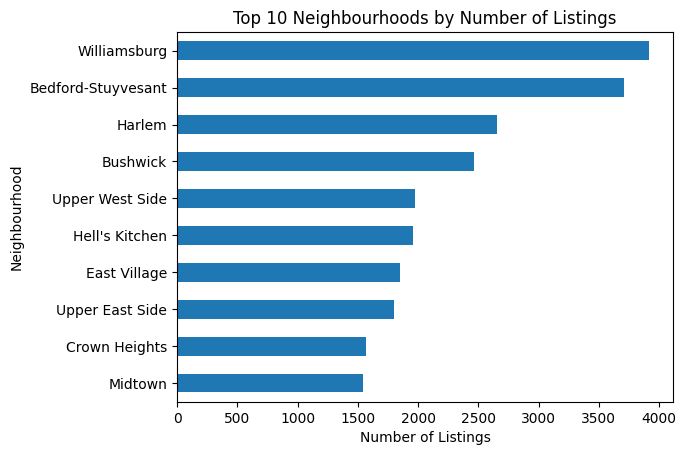

In [571]:
# Count listings in each neighbourhood and select the top ten
neighbourhood_counts = src_dt_clean['neighbourhood_name'].value_counts().head(10)
display(neighbourhood_counts)

# Plot the top ten neighbourhoods
neighbourhood_counts.sort_values().plot(kind='barh')
gph_drw.title('Top 10 Neighbourhoods by Number of Listings')
gph_drw.xlabel('Number of Listings')
gph_drw.ylabel('Neighbourhood')
gph_drw.show()

**Interpretation**  
The most listings are in Williamsburg (3919), Besrc_dord-Stuyvesant (3710) and Harlem (2658). The areas are especially rich in listing supply in the data set.


## Business Question 4 — How does availability differ by room type?

**Business importance**  
Annual availability shows how many days a listing is marked as available. Comparing room types can reveal differences in listing availability, although it does not directly measure demand or occupancy.


,mean,median
accommodation_category,,
Shared room,161.873057,90.0
Entire home/apt,111.926241,42.0
Private room,111.203638,45.0


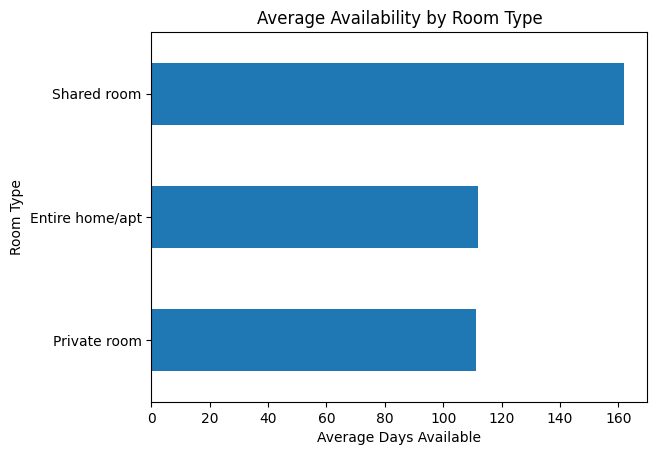

In [572]:
# Compare mean and median annual availability by room type
availability = src_dt_clean.groupby('accommodation_category')['yearly_availability'].agg(['mean','median']).sort_values('mean', ascending=False)
display(availability)

# Plot average available days
availability['mean'].sort_values().plot(kind='barh')
gph_drw.title('Average Availability by Room Type')
gph_drw.xlabel('Average Days Available')
gph_drw.ylabel('Room Type')
gph_drw.show()

**Interpretation**  
Sharing rooms have the highest average availability (161.87 days), compared with 111.93 days for entire homes/apartments and 111.20 days for private rooms. The dataset cannot determine whether these differences are caused by demand, host behaviour or other factors.


## Business Question 5 — Which hosts have the most Airbnb listings?

**Business importance**  
Host concentration indicates whether supply is mainly distributed among individual hosts or concentrated among larger operators.


,,0
host_identifier,host_full_name,
219517861,Sonder (NYC),327
107434423,Blueground,232
30283594,Kara,121
137358866,Kazuya,103
16098958,Jeremy & Laura,96
12243051,Sonder,96
61391963,Corporate Housing,91
22541573,Ken,87
200380610,Pranjal,65


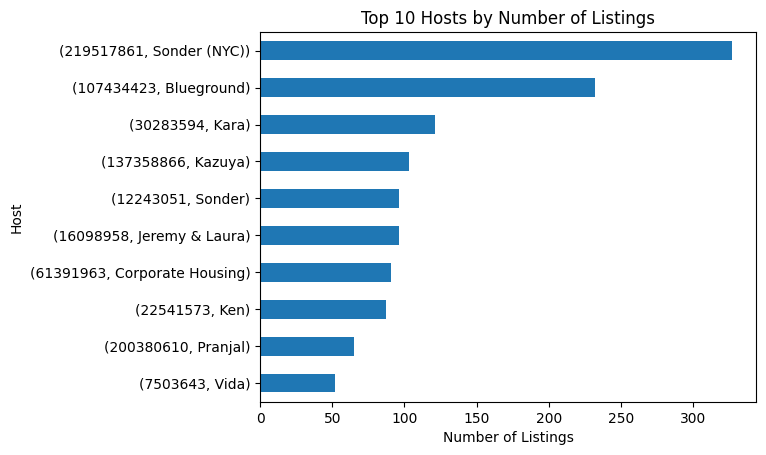

In [573]:
# Count listings for each host using host ID and name
top_hosts = src_dt_clean.groupby(['host_identifier','host_full_name']).size().sort_values(ascending=False).head(10)
display(top_hosts)

# Plot the largest host portfolios.
top_hosts.sort_values().plot(kind='barh')
gph_drw.title('Top 10 Hosts by Number of Listings')
gph_drw.xlabel('Number of Listings')
gph_drw.ylabel('Host')
gph_drw.show()

**Interpretation**  
Sonder (NYC) has the largest portfolio with 327 listings, followed by Blueground with 232. This shows that some operators manage substantially more listings than typical individual hosts.


## Business Question 6 — Which neighbourhood groups have the largest review volume?

**Business importance**  
Review activity provides a measure of customer engagement. Comparing total reviews and reviews per listing gives both market-level and listing-level perspectives.


,total_reviews,average_reviews,listings
neighbourhood_area,,,
Brooklyn,486252,24.197661,20095
Manhattan,454569,20.986565,21660
Queens,156950,27.700318,5666
Bronx,28316,25.977982,1090
Staten Island,11541,30.941019,373


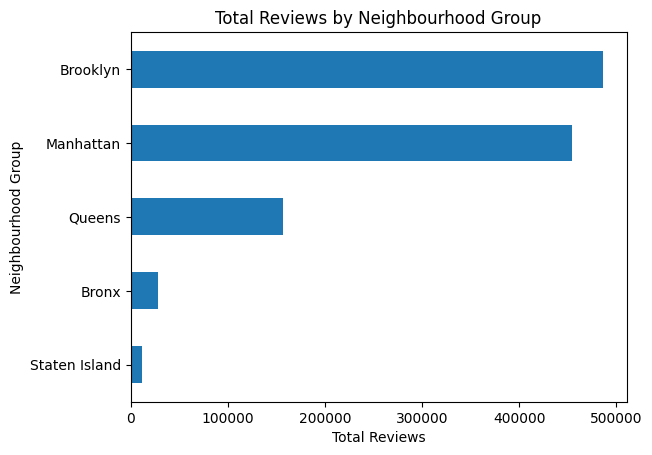

In [574]:
# Calculate total reviews, average reviews and listing count by area.
reviews_area = src_dt_clean.groupby('neighbourhood_area').agg(
    total_reviews=('review_count','sum'),
    average_reviews=('review_count','mean'),
    listings=('listing_id','count')
).sort_values('total_reviews', ascending=False)
display(reviews_area)

# Plot total review volume.
reviews_area['total_reviews'].sort_values().plot(kind='barh')
gph_drw.title('Total Reviews by Neighbourhood Group')
gph_drw.xlabel('Total Reviews')
gph_drw.ylabel('Neighbourhood Group')
gph_drw.show()

**Interpretation**  
Brooklyn has the highest total review volume (486,252), followed by Manhattan (454,569). Staten Island has the highest average reviews per listing (30.94). Total and per-listing measures therefore provide different insights into review activity.


## 5. Overall Findings

There are clear differences in price, supply, availability and review activity identified in the analysis. The average prices are the highest in Manhattan, and entire homes/apartments are the most expensive room type. Williamsburg and Besrc_dord-Stuyvesant are neighborhood areas where listings for supply are more concentrated. The highest average availability is in shared rooms, and the highest reviews per listing is in private rooms. The price/review correlation is very low, indicating that the volume of reviews is not solely driven by price.


## 6. Business Recommendations

**Use both mean and median for pricing decisions.** There is a difference between the mean and the median for Manhattan, as well as for entire homes/apartments; the typical price is higher, but extreme prices may impact averages.

**Monitor high-supply neighbourhoods.** High supply neighbourhoods like Williamsburg and Besrc_dord-Stuyvesant should be monitored when evaluating the competition of new listings and positioning..

**Monitor large host portfolios.** There are large operators like Sonder (NYC) and Blueground that show where supply is focused and can help determine the level of competitive pressure.

**Investigate availability patterns further.** Further study into availability trends be carried out, as the shared rooms have a higher mean availability, but booking and occupancy data will be required to identify the reason..

**Do not use review volume as a price measure.** The correlation is very low, which means other factors like location, room type and market conditions should be taken into account when making pricing decisions..


## 7. Limitations

The dataset describes New York City Airbnb listings from a historical period, so the results should not be treated as current market conditions or generalised to other locations. The analysis is explanatory rather than causal. Reviews are not the same as bookings and cannot be used as a direct measure of occupancy. High-priced observations were retained because they may be legitimate. The dataset also lacks variables such as actual bookings, occupancy, amenities and current market conditions that could explain price or demand.


## 8. Conclusion

This analysis provides an evidence-based view of the New York City Airbnb listing market. It identifies differences in pricing by neighbourhood group and room type, concentrations of listing supply, availability differences and variation in review activity. The findings can support initial pricing and competitive decisions, but stronger business decisions would require current booking, occupancy and market data.


## References

Dgomonov (2019) *New York City Airbnb Open Data*. Kaggle. Available at: https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data (Accessed: 13 September 2026).

Matplotlib (2026) *Matplotlib documentation: pyplot*. Available at: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.html (Accessed: 13 September 2026).

pandas (2026) *pandas documentation: DataFrame.groupby*. Available at: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html (Accessed: 13 September 2026).

Python Software Foundation (2026) *Python 3 documentation*. Available at: https://docs.python.org/3/ (Accessed: 13 September 2026).
